# 데이터셋 검증과 배포 차단

대표2대의 후보만 검증했습니다. 전체20대 확정 데이터 생성은 단위·정답 불확실성 때문에 중단되었습니다. V1에서 본 평가 구간을 독립 미사용 평가라고 주장하지 않습니다.

In [1]:
from pathlib import Path
import os, json, sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert ROOT.name == 'PHM2018-Project-V2'
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT / 'outputs/matplotlib')
import polars as pl
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
figdir = ROOT / 'reports/figures'
figdir.mkdir(parents=True, exist_ok=True)
load = lambda name: json.loads((ROOT / 'outputs' / name).read_text(encoding='utf-8'))


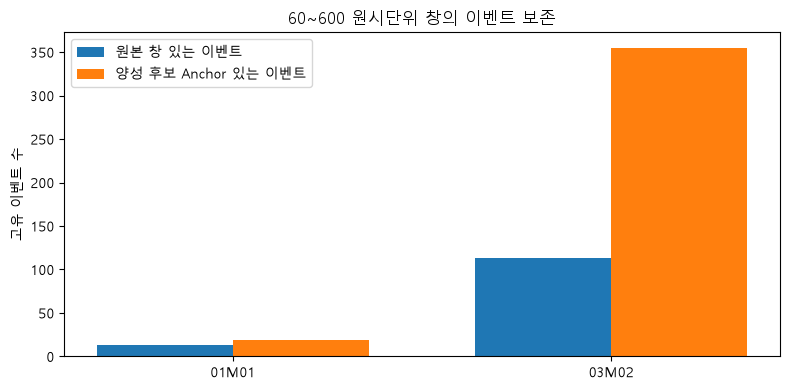

최종 판단: 모델 학습 시작 불가. 승인 데이터 0행.


{'status': 'DIAGNOSTIC_COMPLETE_RELEASE_BLOCKED',
 'v1_files_checked': 2139,
 'v1_metadata_changes': [],
 'v1_integrity_scope': '실행 전후 전체 기존 파일 크기/mtime; 감사 원본60파일 SHA256 별도. V1 전체 전후 해시 검증은 아님',
 'blockers': ['물리 초 단위/변환 미검증; 현재 창은 원시시간 단위 진단용',
  'Fault 이력의 유효 범위와 TTF Null 검열 한계 미확정',
  '고장 후 정비 종료 시각/구간 미확정'],
 'approved_training_rows': 0}

In [2]:
checks = load('validation.json')
assert all(not c['issues'] for c in checks)
assert all(c['approved_training_rows'] == 0 for c in checks)
pilot = load('pilot_summary.json')
fig, ax = plt.subplots(figsize=(8,4))
for i, p in enumerate(pilot):
    ax.bar(i-.18, p['events_with_raw_window'], width=.36, color='tab:blue', label='원본 창 있는 이벤트' if i==0 else None)
    ax.bar(i+.18, p['events_with_positive_anchor'], width=.36, color='tab:orange', label='양성 후보 Anchor 있는 이벤트' if i==0 else None)
ax.set_xticks(range(len(pilot)), [p['tool'] for p in pilot]); ax.set_ylabel('고유 이벤트 수')
ax.set_title('60~600 원시단위 창의 이벤트 보존'); ax.legend()
fig.tight_layout(); fig.savefig(figdir / '04_event_preservation.png', dpi=130); plt.show()
print('최종 판단: 모델 학습 시작 불가. 승인 데이터 0행.')
load('run_status.json')

## 그래프 해석과 한계

미래 이벤트 이력과 입력 관측 가능성은 별개입니다. 따라서 센서 없는 격자에도 양성 후보가 있을 수 있으며, 사용 가능한 입력까지 확보한 비율은 이벤트별 observed_grid_anchors와 history900_positive_anchors를 함께 확인해야 합니다. 태그 충돌과 60 미만 제외도 보존율에 영향을 줍니다. 실제2대의 검증 통과는 전체20대 학습 데이터의 검증 완료를 의미하지 않습니다.

상세 결과는 `reports/`의 한국어 보고서와 `outputs/`의 수치 파일을 참조하세요.